<a href="https://colab.research.google.com/github/nicolasrporto/Python/blob/main/DadosIbovespa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

3
10140.05
365
0.00277777777
0.002
0.015
1
2.600542e+04
2.602612e+04
2.600569e+04
2.598527e+04
2.600596e+04
2.598555e+04
2.596515e+04
2.594476e+04
2.592440e+04
2.590405e+04
2.592467e+04
2.590432e+04
2.588398e+04
2.590459e+04
2.588425e+04
2.590486e+04
2.592549e+04
2.590513e+04
2.588480e+04
2.586448e+04
2.012900e+04
2.014503e+04
2.016107e+04
2.014524e+04
2.012943e+04
2.014545e+04
2.016149e+04
2.014566e+04
2.016170e+04
2.017775e+04
2.016191e+04
2.017796e+04
2.019403e+04
2.021010e+04
2.019424e+04
2.017839e+04
2.019445e+04
2.021053e+04
2.019466e+04
2.021074e+04
1.521530e+04
1.522742e+04
1.521546e+04
1.520352e+04
1.521562e+04
1.522773e+04
1.523986e+04
1.522789e+04
1.524002e+04
1.525215e+04
1.524018e+04
1.525231e+04
1.524034e+04
1.522837e+04
1.521642e+04
1.522853e+04
1.524066e+04
1.522869e+04
1.524082e+04
1.525295e+04


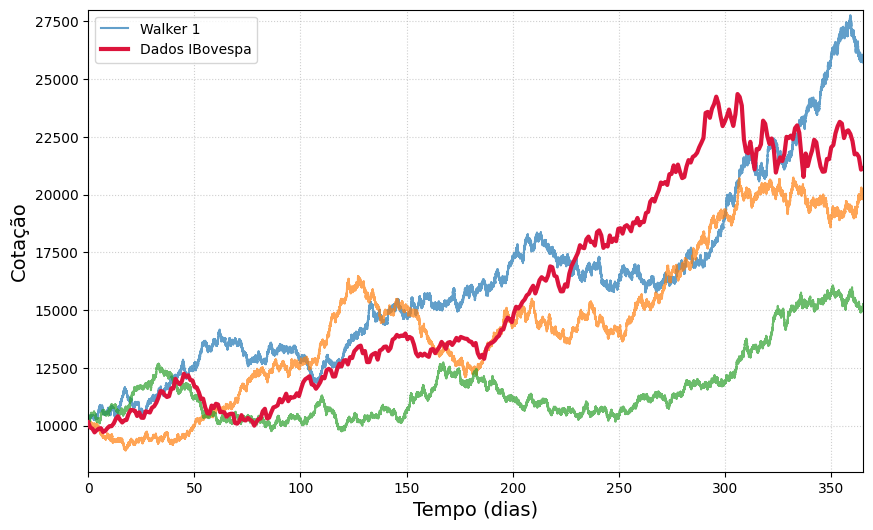

In [6]:
import numpy as np
import matplotlib.pyplot as plt

Nc = int(input()) # número de caminhantes
P0 = float(input()) #o valor inicial do índice
tf = float(input()) #tempo final das simulações
dt = float(input()) #passo temporal
mu = float(input()) #o parâmetro da componente linear da EDE
sigma = float(input()) #o parâmetro da componente aleatória da EDE
seed = int(input())



IbovNum = np.genfromtxt('IbovData.mat', delimiter=',')

# Configuração da semente aleatória
np.random.seed(seed)

# Número exato de passos
n_steps = int(tf / dt)

# Matriz que armazenará as simulações
# Cada linha deve conter uma simulação diferente, com as colunas correspondendo aos valores do índice Ibovespa nos diferentes instantes.
P = np.zeros((Nc, n_steps))

# Execução da simulação (Loop de tempo dentro do loop de Nc walkers)
for iwalker in range(Nc):
    P[iwalker, 0] = P0  # Condição inicial

    for n in range(n_steps - 1):
        # Gerador uniforme
        random_val = np.random.uniform(0.0, 1.0)

        # Caminhada aleatória discreta (+1 ou -1 com 50% de chance)
        if random_val < 0.5:
            r_n = -1.0
        else:
            r_n = 1.0

        # Delta W_n com o dt correto na escala infinitesimal
        dW_n = r_n * np.sqrt(dt)

        # Equação de Euler-Maruyama estrita da imagem 1
        dP_n = mu * P[iwalker, n] * dt + sigma * P[iwalker, n] * dW_n
        P[iwalker, n + 1] = P[iwalker, n] + dP_n

#Saída
for iwalker in range(Nc):
    for it in range(-20, 0):
        print("{:10.6e}".format(P[iwalker, it]))


# Leitura corrigida dos dados reais do arquivo texto 'IbovData.mat'
dados_reais = []
with open('IbovData.mat', 'r') as file:
    for line in file:
        line_clean = line.strip()
        if not line_clean or line_clean.startswith('#') or 'name:' in line_clean or 'type:' in line_clean:
            continue
        try:
            dados_reais.append(float(line_clean))
        except ValueError:
            continue

# Sincronização: Seleciona apenas os primeiros dias para bater com a simulação (tf = 365)
dados_reais = np.array(dados_reais)[:365]

#gráfico comparativo
t_sim = np.linspace(0, tf, n_steps)
t_real = np.linspace(0, len(dados_reais), len(dados_reais))

plt.figure(figsize=(10, 6))

# Plot das realizações simuladas (Walkers)
for i in range(Nc):
    plt.plot(t_sim, P[i, :], alpha=0.7, label=f'Walker {i+1}' if i==0 else "")

# Plot dos dados reais históricos limitados ao período correto
plt.plot(t_real, dados_reais, color='crimson', linewidth=3, label='Dados IBovespa', zorder=5)

plt.xlabel('Tempo (dias)', fontsize=14)
plt.ylabel('Cotação', fontsize=14)
plt.xlim(0, tf)
plt.ylim(8000, 28000) # Ajuste de limites para focar na região correta
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

